# Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, confusion_matrix, classification_report
from sklearn.tree import DecisionTreeClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import joblib

# Load Data

In [ ]:
df=pd.read_csv('/content/Heart_risk_dataset.csv',na_values=['?',' '])

# viewing data:

In [ ]:
df.shape

(22500, 11)

In [ ]:
df.head()

,patient_id,age,gender,smoker_status,diabetes_history,heart_rate,systolic_blood_pressure,oxygen_saturation,chest_pain_severity,body_temperature,risk_level
0,PT2-000001,31,Male,No,No,67,111,98.6,0.0,36.4,Low Risk
1,PT2-000002,56,Female,No,No,84,146,95.1,1.8,37.1,Low Risk
2,PT2-000003,54,Female,Yes,Yes,131,179,82.8,7.8,37.5,Critical Risk
3,PT2-000004,78,Female,No,No,94,153,96.0,2.4,36.5,Moderate Risk
4,PT2-000005,47,Female,Yes,No,65,128,97.0,3.4,36.4,Low Risk


In [ ]:
df.tail()

,patient_id,age,gender,smoker_status,diabetes_history,heart_rate,systolic_blood_pressure,oxygen_saturation,chest_pain_severity,body_temperature,risk_level
22495,PT2-022496,43,Female,Yes,Yes,79,155,97.7,1.3,37.1,Moderate Risk
22496,PT2-022497,51,Female,Yes,Yes,122,186,83.8,7.5,37.5,Critical Risk
22497,PT2-022498,79,Male,No,Yes,84,151,97.0,0.4,36.9,Moderate Risk
22498,PT2-022499,33,Female,Yes,No,64,96,96.1,0.0,36.9,Moderate Risk
22499,PT2-022500,84,Female,Yes,No,103,176,90.1,4.7,37.0,High Risk


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22500 entries, 0 to 22499
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   patient_id               22500 non-null  object 
 1   age                      22500 non-null  int64  
 2   gender                   22500 non-null  object 
 3   smoker_status            22500 non-null  object 
 4   diabetes_history         22500 non-null  object 
 5   heart_rate               22500 non-null  int64  
 6   systolic_blood_pressure  22500 non-null  int64  
 7   oxygen_saturation        22500 non-null  float64
 8   chest_pain_severity      22500 non-null  float64
 9   body_temperature         22500 non-null  float64
 10  risk_level               22500 non-null  object 
dtypes: float64(3), int64(3), object(5)
memory usage: 1.9+ MB


In [ ]:
df.describe()

,age,heart_rate,systolic_blood_pressure,oxygen_saturation,chest_pain_severity,body_temperature
count,22500.000000,22500.000000,22500.000000,22500.000000,22500.000000,22500.000000
mean,59.067778,90.530222,153.380267,93.568880,3.293822,36.925711
std,18.729212,21.418896,27.014243,5.052325,2.578688,0.424039
min,18.000000,36.000000,72.000000,76.000000,0.000000,35.100000
25%,45.000000,74.000000,132.000000,91.000000,1.100000,36.600000
50%,61.000000,87.000000,158.000000,95.200000,2.700000,36.900000
75%,74.000000,104.000000,174.000000,97.400000,5.400000,37.200000
max,92.000000,174.000000,225.000000,100.000000,10.000000,39.100000


# data cleaning

In [ ]:
df.isnull().sum()

,0
patient_id,0
age,0
gender,0
smoker_status,0
diabetes_history,0
heart_rate,0
systolic_blood_pressure,0
oxygen_saturation,0
chest_pain_severity,0
body_temperature,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.drop('patient_id',axis=1,inplace=True)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22500 entries, 0 to 22499
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      22500 non-null  int64  
 1   gender                   22500 non-null  object 
 2   smoker_status            22500 non-null  object 
 3   diabetes_history         22500 non-null  object 
 4   heart_rate               22500 non-null  int64  
 5   systolic_blood_pressure  22500 non-null  int64  
 6   oxygen_saturation        22500 non-null  float64
 7   chest_pain_severity      22500 non-null  float64
 8   body_temperature         22500 non-null  float64
 9   risk_level               22500 non-null  object 
dtypes: float64(3), int64(3), object(4)
memory usage: 1.7+ MB


# EDA

<Axes: xlabel='count', ylabel='risk_level'>

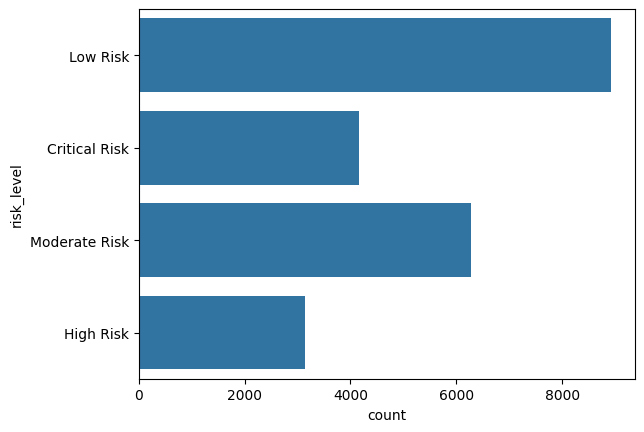

In [ ]:
sns.countplot(df['risk_level'])

In [ ]:
X=df.drop('risk_level',axis=1)
y=df['risk_level']

In [ ]:
numerical=X.select_dtypes(include=np.number).columns
categorical=X.select_dtypes(exclude=np.number).columns

In [ ]:
numerical

Index(['age', 'heart_rate', 'systolic_blood_pressure', 'oxygen_saturation',
       'chest_pain_severity', 'body_temperature'],
      dtype='object')

In [ ]:
categorical

Index(['gender', 'smoker_status', 'diabetes_history'], dtype='object')

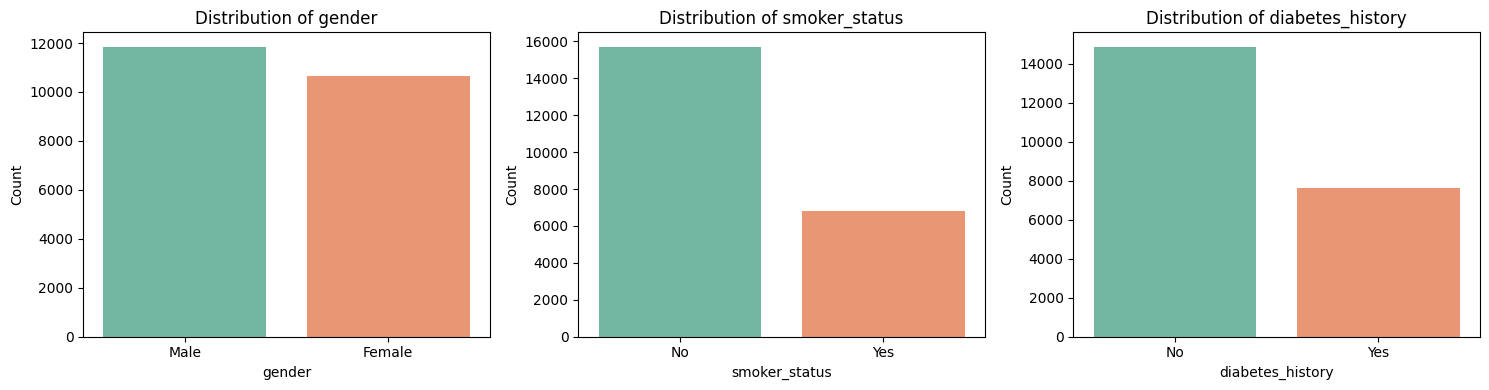

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, col in enumerate(categorical):

    sns.countplot(data=df, x=col, ax=axes[i],palette='Set2',hue=col)

    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Count")

plt.tight_layout()
plt.show()

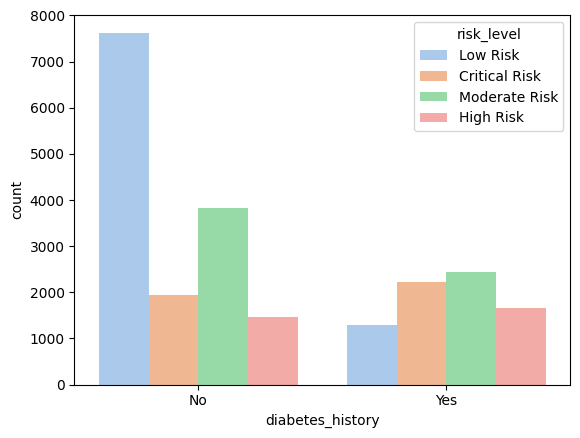

In [ ]:
sns.countplot(
    data=df,
    x="diabetes_history",
    hue="risk_level",
    palette="pastel"
)

plt.show()

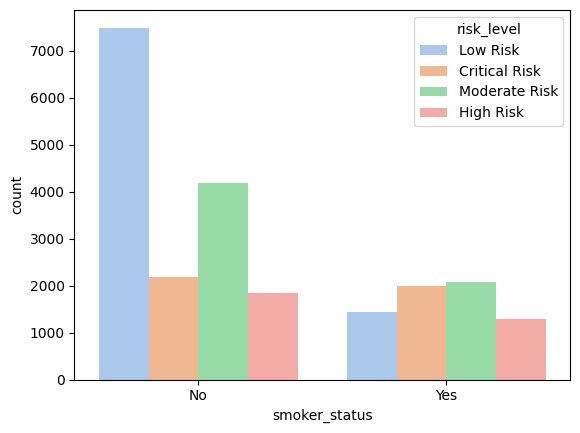

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(
    data=df,
    x="smoker_status",
    hue="risk_level",
    palette="pastel"
)

plt.show()

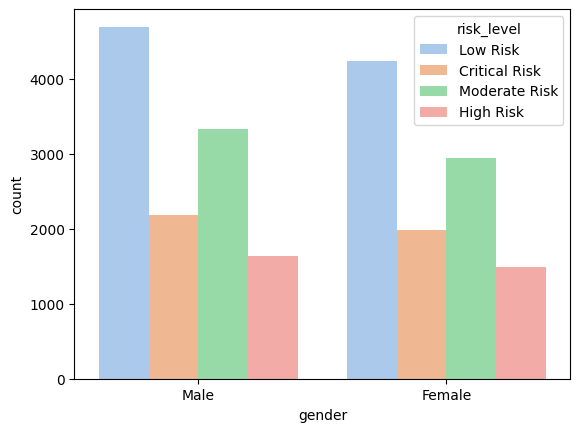

In [ ]:
sns.countplot(
    data=df,
    x="gender",
    hue="risk_level",
    palette="pastel"
)

plt.show()

<Axes: >

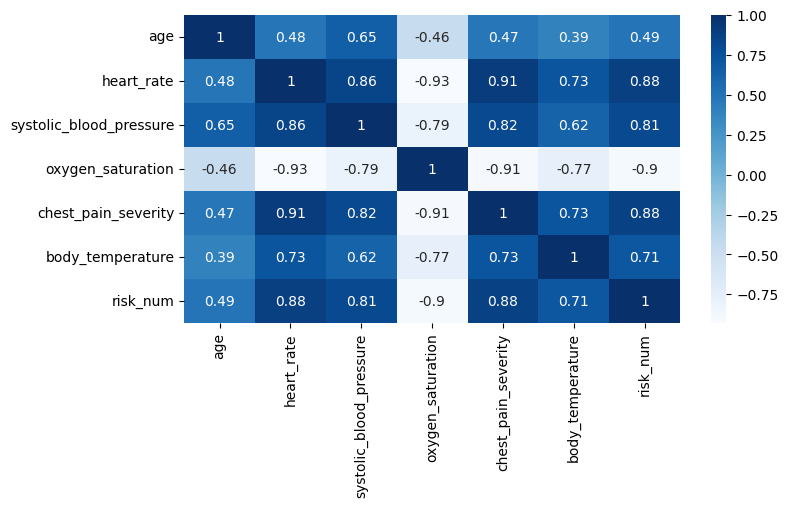

In [ ]:
plt.figure(figsize=(8, 4))
df['risk_num'] = df['risk_level'].map({'Low Risk':0,'Moderate Risk':1,'High Risk':2,'Critical Risk':3})
sns.heatmap(df.select_dtypes('number').corr(), annot=True,cmap='Blues')

<Axes: xlabel='risk_level', ylabel='oxygen_saturation'>

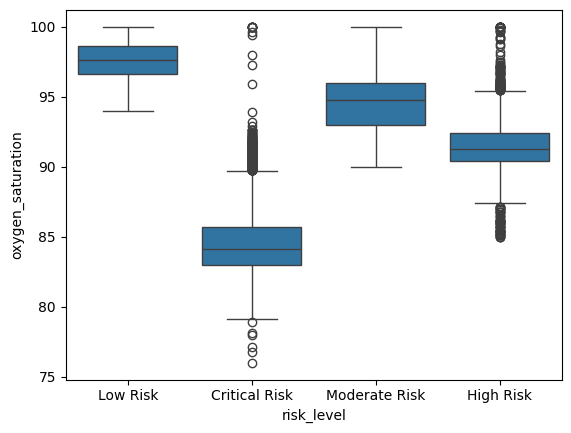

In [ ]:
sns.boxplot(data=df, x='risk_level', y='oxygen_saturation')

<Axes: xlabel='risk_level', ylabel='chest_pain_severity'>

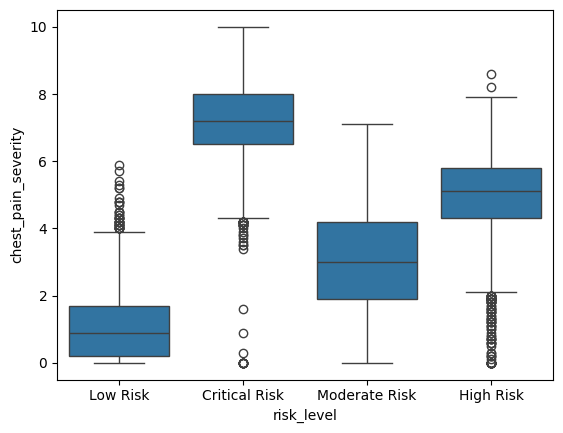

In [ ]:
sns.boxplot(data=df, x='risk_level', y='chest_pain_severity')

<Axes: xlabel='risk_level', ylabel='heart_rate'>

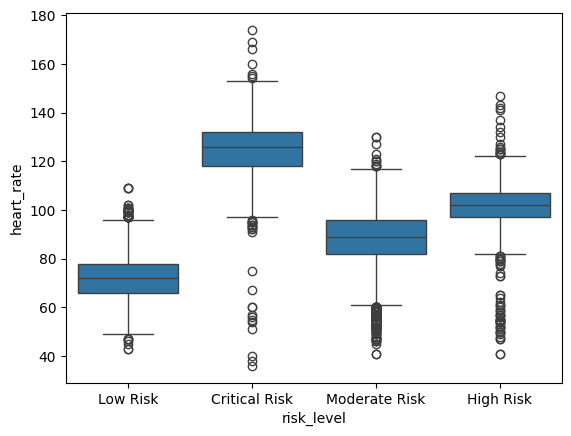

In [ ]:
sns.boxplot(data=df, x='risk_level', y='heart_rate')

In [ ]:
df.drop('risk_num',axis=1,inplace=True)

# Encoding

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical)
    ])

# Train_Test_Split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Logistic Regression

In [ ]:
lr_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(class_weight='balanced',random_state=42))

])

In [ ]:
lr_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  Index(['age', 'heart_rate', 'systolic_blood_pressure', 'oxygen_saturation',
       'chest_pain_severity', 'body_temperature'],
      dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['gender', 'smoker_status', 'diabetes_history'], dtype='object'))])),
                ('model',
                 LogisticRegression(class_weight='balanced', random_state=42))])

In [ ]:
y_lr_test_pred = lr_pipeline.predict(X_test)
y_lr_train_pred = lr_pipeline.predict(X_train)

In [ ]:
print('Accuracy_test: ',accuracy_score(y_test, y_lr_test_pred))

print('Recall_test: ',recall_score(y_test, y_lr_test_pred,average='weighted'))

print('Precision_test: ',precision_score(y_test, y_lr_test_pred,average='weighted'))

print('F1_test: ',f1_score(y_test, y_lr_test_pred,average='weighted'))
print('confusion_matrix: \n',confusion_matrix(y_test, y_lr_test_pred))
print('classification_report: \n',classification_report(y_test, y_lr_test_pred))

Accuracy_test:  0.8655555555555555
Recall_test:  0.8655555555555555
Precision_test:  0.8717217217797542
F1_test:  0.8670701481454927
confusion_matrix: 
 [[ 743   55    2    0]
 [  17  606    5   46]
 [   0    0 1562  206]
 [   0  162  112  984]]
classification_report: 
                precision    recall  f1-score   support

Critical Risk       0.98      0.93      0.95       800
    High Risk       0.74      0.90      0.81       674
     Low Risk       0.93      0.88      0.91      1768
Moderate Risk       0.80      0.78      0.79      1258

     accuracy                           0.87      4500
    macro avg       0.86      0.87      0.86      4500
 weighted avg       0.87      0.87      0.87      4500



In [ ]:
print('Accuracy_train: ',accuracy_score(y_train, y_lr_train_pred))
print('Recall_train: ',recall_score(y_train, y_lr_train_pred,average='weighted'))
print('Precision_train: ',precision_score(y_train, y_lr_train_pred,average='weighted'))
print('F1_train: ',f1_score(y_train, y_lr_train_pred,average='weighted'))

Accuracy_train:  0.8516666666666667
Recall_train:  0.8516666666666667
Precision_train:  0.8615337464316261
F1_train:  0.8542630354764466


# Decision Tree Classifier

In [ ]:
dt_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DecisionTreeClassifier(class_weight='balanced',random_state=42,max_depth=5,min_samples_leaf=7))
])

In [ ]:
dt_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  Index(['age', 'heart_rate', 'systolic_blood_pressure', 'oxygen_saturation',
       'chest_pain_severity', 'body_temperature'],
      dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['gender', 'smoker_status', 'diabetes_history'], dtype='object'))])),
                ('model',
                 DecisionTreeClassifier(class_weight='balanced', max_depth=5,
                                        min_samples_leaf=7, random_state=42))])

In [ ]:
y_dt_test_pred = dt_pipeline.predict(X_test)
y_dt_train_pred = dt_pipeline.predict(X_train)

In [ ]:
print('Accuracy_test: ',accuracy_score(y_test, y_dt_test_pred))

print('Recall_test: ',recall_score(y_test, y_dt_test_pred,average='weighted'))

print('Precision_test: ',precision_score(y_test, y_dt_test_pred,average='weighted'))

print('F1_test: ',f1_score(y_test, y_dt_test_pred,average='weighted'))
print('classification_report: \n',classification_report(y_test, y_dt_test_pred))

Accuracy_test:  0.8946666666666667
Recall_test:  0.8946666666666667
Precision_test:  0.9031451519835769
F1_test:  0.8965664611370222
classification_report: 
                precision    recall  f1-score   support

Critical Risk       0.99      0.85      0.91       800
    High Risk       0.74      0.91      0.82       674
     Low Risk       0.96      0.93      0.94      1768
Moderate Risk       0.86      0.87      0.86      1258

     accuracy                           0.89      4500
    macro avg       0.89      0.89      0.88      4500
 weighted avg       0.90      0.89      0.90      4500



In [ ]:
param_grid = {
    'model__criterion': ['gini', 'entropy', 'log_loss'],
    'model__max_depth': [None, 5, 10, 15, 20],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4]
}

grid_search = GridSearchCV(
    estimator=dt_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV Macro F1:", grid_search.best_score_)

best_dt = grid_search.best_estimator_


Best Parameters: {'model__criterion': 'entropy', 'model__max_depth': 15, 'model__min_samples_leaf': 2, 'model__min_samples_split': 5}
Best CV Macro F1: 0.9537127607059241


In [ ]:
y_dt_hyper_pred = best_dt.predict(X_test)
y_dt_hyper_pred_train = best_dt.predict(X_train)

In [ ]:
print('Accuracy_test: ',accuracy_score(y_test, y_dt_hyper_pred))
print('Recall_test: ',recall_score(y_test, y_dt_hyper_pred,average='weighted'))
print('Precision_test: ',precision_score(y_test, y_dt_hyper_pred,average='weighted'))
print('F1_test: ',f1_score(y_test, y_dt_hyper_pred,average='weighted'))
print('confusion_matrix: \n',confusion_matrix(y_test, y_dt_hyper_pred))
print('classification_report: \n',classification_report(y_test, y_dt_hyper_pred))

Accuracy_test:  0.9635555555555556
Recall_test:  0.9635555555555556
Precision_test:  0.9642947778418209
F1_test:  0.9637740151288534
confusion_matrix: 
 [[ 771   29    0    0]
 [  12  642    0   20]
 [   0    0 1731   37]
 [   0   44   22 1192]]
classification_report: 
                precision    recall  f1-score   support

Critical Risk       0.98      0.96      0.97       800
    High Risk       0.90      0.95      0.92       674
     Low Risk       0.99      0.98      0.98      1768
Moderate Risk       0.95      0.95      0.95      1258

     accuracy                           0.96      4500
    macro avg       0.96      0.96      0.96      4500
 weighted avg       0.96      0.96      0.96      4500



In [ ]:
print('Accuracy_train: ',accuracy_score(y_train, y_dt_hyper_pred_train))
print('Recall_train: ',recall_score(y_train, y_dt_hyper_pred_train,average='weighted'))
print('Precision_train: ',precision_score(y_train, y_dt_hyper_pred_train,average='weighted'))
print('F1_train: ',f1_score(y_train, y_dt_hyper_pred_train,average='weighted'))
print('confusion_matrix: \n',confusion_matrix(y_train, y_dt_hyper_pred_train))
print('classification_report: \n',classification_report(y_train, y_dt_hyper_pred_train))

Accuracy_train:  0.9895555555555555
Recall_train:  0.9895555555555555
Precision_train:  0.9896869090868486
F1_train:  0.9895819470366602
confusion_matrix: 
 [[3335   28    0    0]
 [   6 2455    0    3]
 [   0    0 7089   70]
 [   2   59   20 4933]]
classification_report: 
                precision    recall  f1-score   support

Critical Risk       1.00      0.99      0.99      3363
    High Risk       0.97      1.00      0.98      2464
     Low Risk       1.00      0.99      0.99      7159
Moderate Risk       0.99      0.98      0.98      5014

     accuracy                           0.99     18000
    macro avg       0.99      0.99      0.99     18000
 weighted avg       0.99      0.99      0.99     18000



In [ ]:
print(grid_search.best_params_)
print(grid_search.best_score_)

{'model__criterion': 'entropy', 'model__max_depth': 15, 'model__min_samples_leaf': 2, 'model__min_samples_split': 5}
0.9537127607059241


# Save Model

In [ ]:
joblib.dump(best_dt,'model.pkl')

['model.pkl']

In [ ]:
final_model = joblib.load('model.pkl')

In [ ]:
y_pread_final = final_model.predict(X_test)

In [ ]:
print(accuracy_score(y_test,y_pread_final))

0.9635555555555556


In [ ]:
pred = final_model.predict(X_test)